# Convergence For Policy Evaluation

Iterative policy evaluation and many other policy iteration methods converge because of the 
**$\gamma$-contracting property of the Bellman update operator** in finite MDPs.

This property does not apply if $\gamma = 1$, but convergence is sill guaranteed if **episodes always terminate** (i.e., reach an absorbing state with al future rewards being 0). 


## Installation and Setup

In [ ]:
# uncomment if needed
# %pip install gym-classics2

In [22]:
import numpy as np
np.set_printoptions(precision=2)

In [23]:
import gymnasium as gym
import gym_classics2

## Define a Non-terminating Maze

We define here the L-maze, but without a terminating goal state. Getting to the goal state just sends the agent back to the start state.

We use a step cost of 1. To incentivize the agent to go to the goal, we use a reward of 100 for the goal state minus 1 for getting there. 

In [24]:
from gym_classics2.envs.abstract.gridworld import Gridworld

class LMazeGridworld_non_terminating(Gridworld):
    layout = """
|          |
|        G |
|          |
| XXXXXX   |
|      X   |
|      X   |
|      X   |
|  S   X   |
|          |
|          |
"""

    def __init__(self, tabular = True):
        super().__init__(self.layout, goal_reward=99.0, step_reward=-1.0, tabular=tabular)

    def _next_state(self, state, action):
        if state in self._goals:
            next_state = self.start_states[0]  # Note: Reset to start state if in goal state
        else:
            next_state = self._move(state, action)
        
        if self._is_blocked(next_state):
            next_state = state
        
        # clamp checks if the coordinate is out of bounds. 1.0 is the probability.
        return self._clamp(next_state), 1.0

    def _reward(self, state, action, next_state):      
        if next_state in self._goals: 
            return self._goal_reward  
        
        return self._step_reward

    def _done(self, state, action, next_state):
        return False  # The episode never ends, even if the goal is reached

gym.register('LMaze_non_terminating-v0', entry_point=LMazeGridworld_non_terminating)

/home/mhahsler/miniconda3/envs/reinforcement-learning/lib/python3.12/site-packages/gymnasium/envs/registration.py:637: UserWarning: WARN: Overriding environment LMaze_non_terminating-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")


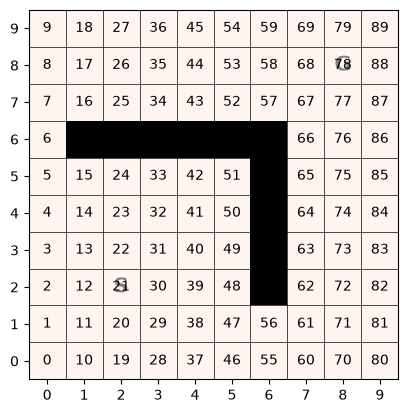

In [25]:
gym_env = gym.make('LMaze_non_terminating-v0', tabular = True)
env = gym_env.unwrapped
env.image()

## Define a Policy

We need to first define a policy we want to evaluate.
Here we find the optimal policy and value function using value iteration with $\gamma = .9$

Value Iteration: 97it [00:00, 291.56it/s]


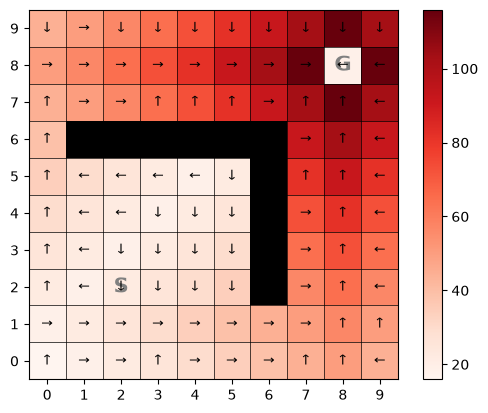

In [26]:
from gym_classics2.algorithms.dynamic_programming import value_iteration, policy_evaluation
from gym_classics2.algorithms.policy import greedy_policy

V_star = value_iteration(env, discount=.9)
pol_star = greedy_policy(V_star, env)
env.image(V_star, policy = pol_star)

## Policy Evaluation with $\gamma < 1$

Evaluation always converges for $\gamma < 1$


Converged after 96 sweeps.


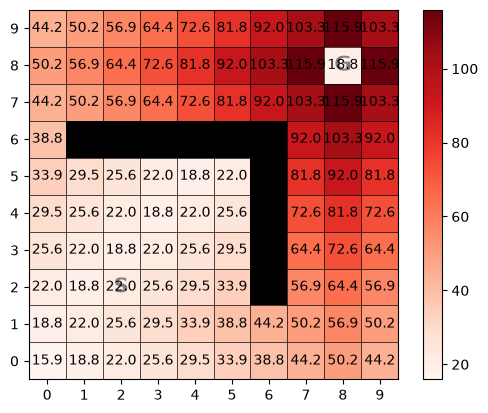

 +44.21   +50.23   +56.92   +64.36   +72.62   +81.80   +92.00  +103.33  +115.93  +103.33  
 +50.23   +56.92   +64.36   +72.62   +81.80   +92.00  +103.33  +115.93   +18.81  +115.93  
 +44.21   +50.23   +56.92   +64.36   +72.62   +81.80   +92.00  +103.33  +115.93  +103.33  
 +38.79                                                         +92.00  +103.33   +92.00  
 +33.91   +29.52   +25.57   +22.01   +18.81   +22.01            +81.80   +92.00   +81.80  
 +29.52   +25.57   +22.01   +18.81   +22.01   +25.57            +72.62   +81.80   +72.62  
 +25.57   +22.01   +18.81   +22.01   +25.57   +29.52            +64.36   +72.62   +64.36  
 +22.01   +18.81   +22.01   +25.57   +29.52   +33.91            +56.92   +64.36   +56.92  
 +18.81   +22.01   +25.57   +29.52   +33.91   +38.79   +44.21   +50.23   +56.92   +50.23  
 +15.93   +18.81   +22.01   +25.57   +29.52   +33.91   +38.79   +44.21   +50.23   +44.21  


In [27]:
V = policy_evaluation(env, discount=.9, policy=pol_star, verbose =True)
env.image(V, labels = [np.round(v, 1) for v in V])
env.print(V)

## Policy Evaluation with $\gamma = 1$

There is no convergence guarantee.


Reached maximum number of backups (100) without convergence.


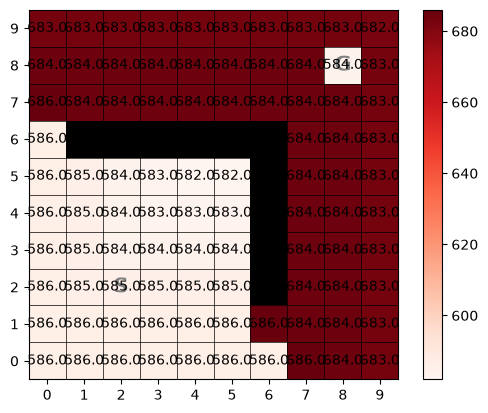

In [28]:
V = policy_evaluation(env, discount=1, policy=pol_star, max_backups=100, verbose=True)
env.image(V, labels = True)

In [29]:
env.print(V)

+683.00  +683.00  +683.00  +683.00  +683.00  +683.00  +683.00  +683.00  +683.00  +682.00  
+684.00  +684.00  +684.00  +684.00  +684.00  +684.00  +684.00  +684.00  +584.00  +683.00  
+686.00  +684.00  +684.00  +684.00  +684.00  +684.00  +684.00  +684.00  +684.00  +683.00  
+586.00                                                        +684.00  +684.00  +683.00  
+586.00  +585.00  +584.00  +583.00  +582.00  +582.00           +684.00  +684.00  +683.00  
+586.00  +585.00  +584.00  +583.00  +583.00  +583.00           +684.00  +684.00  +683.00  
+586.00  +585.00  +584.00  +584.00  +584.00  +584.00           +684.00  +684.00  +683.00  
+586.00  +585.00  +585.00  +585.00  +585.00  +585.00           +684.00  +684.00  +683.00  
+586.00  +586.00  +586.00  +586.00  +586.00  +586.00  +686.00  +684.00  +684.00  +683.00  
+586.00  +586.00  +586.00  +586.00  +586.00  +586.00  +586.00  +686.00  +684.00  +683.00  


The algorithm only stops because of the `max_backups` parameter, that stops the evaluation after the set number of
sweeps over the states. See how the value function increases with stopping after more backups. The evaluation does not converge! 

In [31]:
V = policy_evaluation(env, discount=1, policy=pol_star, max_backups=1000, verbose =True)

env.print(V)


Reached maximum number of backups (1000) without convergence.
+6545.00  +6545.00  +6545.00  +6545.00  +6545.00  +6545.00  +6545.00  +6545.00  +6545.00  +6544.00  
+6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6446.00  +6545.00  
+6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6545.00  
+6546.00                                                              +6546.00  +6546.00  +6545.00  
+6546.00  +6545.00  +6544.00  +6543.00  +6542.00  +6542.00            +6546.00  +6546.00  +6545.00  
+6548.00  +6547.00  +6546.00  +6545.00  +6543.00  +6543.00            +6546.00  +6546.00  +6545.00  
+6448.00  +6447.00  +6446.00  +6546.00  +6544.00  +6544.00            +6546.00  +6546.00  +6545.00  
+6448.00  +6447.00  +6447.00  +6547.00  +6545.00  +6545.00            +6546.00  +6546.00  +6545.00  
+6448.00  +6448.00  +6448.00  +6548.00  +6546.00  +6546.00  +6546.00  +6546.00  +6546.00  +6545.00  
+6448.00  +6448.00  +6448.00

## Policy Evaluation with $\gamma = 1$ where the Policy Reaches a Terminating State 

Convergence is also guaranteed if the
policy reaches a terminating state (an absorbing state where the episode ends).

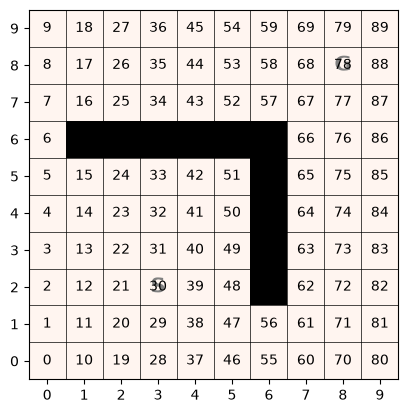

In [32]:
gym_env = gym.make('LMaze-v0', goal_reward = 99.0, step_reward =-1.0, tabular = True)
env = gym_env.unwrapped
env.image()


Converged after 16 sweeps.


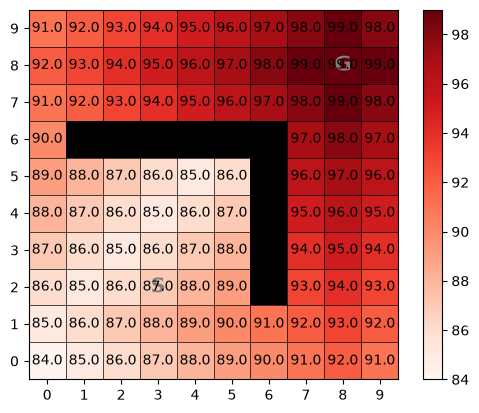

In [33]:
V = policy_evaluation(env, discount=1, policy=pol_star, verbose = True)
env.image(V, labels = True)

We see that the value function for this undiscounted problem shows exactly 100 minus the number of steps it takes the optimal policy to get to the goal. 

## Policy Evaluation with $\gamma = 1$ where the Policy Does not reaches a Terminating State 

This does not converge.

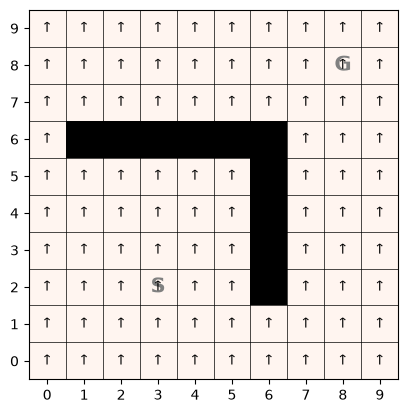

In [34]:
pol = np.zeros(len(pol_star))
env.image(policy = pol)

In [35]:
V = policy_evaluation(env, discount=1, policy=pol, max_backups=100, verbose = True)
env.print(V)


Reached maximum number of backups (100) without convergence.
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00   -99.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00   +99.00  -100.00  
-100.00                                                        -100.00   +98.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00           -100.00   +97.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00           -100.00   +96.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00           -100.00   +95.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00           -100.00   +94.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00   +93.00  -100.00  
-100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00  -100.00   +92.00  -100.00  


In [36]:
V = policy_evaluation(env, discount=1, policy=pol, max_backups=1000, verbose = True)
env.print(V)


Reached maximum number of backups (1000) without convergence.
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00   -999.00  -1000.00  
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00    +99.00  -1000.00  
-1000.00                                                              -1000.00    +98.00  -1000.00  
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00            -1000.00    +97.00  -1000.00  
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00            -1000.00    +96.00  -1000.00  
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00            -1000.00    +95.00  -1000.00  
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00            -1000.00    +94.00  -1000.00  
-1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00  -1000.00    +93.00  -1000.00  
-1000.00  -1000.00  -1000.00

No convergence, and the value function estimate is just an artifact of using `max_backups`.

Using $\gamma < 1$ leads again to convergence.

In [38]:
V = policy_evaluation(env, discount=.9, policy=pol, verbose =True)
env.print(V)


Converged after 66 sweeps.
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -8.99   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99  +99.00   -9.99  
 -9.99                                                   -9.99  +88.10   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99           -9.99  +78.29   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99           -9.99  +69.46   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99           -9.99  +61.51   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99           -9.99  +54.36   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99  +47.93   -9.99  
 -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99   -9.99  +42.13   -9.99  


&copy; 2026 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)